<a href="https://colab.research.google.com/github/jurados/alercehackton2026/blob/main/ZTF_candidates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.colors

from astropy.timeseries import LombScargle
from astropy.coordinates import SkyCoord, GeocentricTrueEcliptic
import astropy.units as u

from alerce.core import Alerce
from tqdm.auto import tqdm

Resolved 69 packages in 154ms                                        
Installed 1 package in 35ms                                      
 + pyarrow==26.0.1


In [6]:
# Create an Alerce client
client = Alerce()

print("Querying classifiers for ZTF survey...")
print(f"{help(client)}")

Querying classifiers for ZTF survey...
Help on Alerce in module alerce.core object:

class Alerce(alerce.common_search.AlerceCommonSearch, alerce.crossmatch.AlerceXmatch, alerce.common_stamps.AlerceCommonStamps)
 |  Alerce(ztf_backend: Literal['legacy', 'multisurvey'] = 'legacy', **kwargs)
 |
 |  The ALeRCE Client for accessing astronomical data from multiple surveys.
 |
 |  This is the main entry point for the ALeRCE Python Client. It provides unified
 |  access to query astronomical objects, photometry, classifications, stamps, and
 |  perform crossmatching operations across multiple surveys.
 |
 |  Examples
 |  --------
 |  Basic usage:
 |
 |  >>> from alerce.core import Alerce
 |  >>> client = Alerce()
 |
 |  Query objects from ZTF:
 |
 |  >>> objects = client.query_objects(
 |  ...     survey="ztf",
 |  ...     ra=10.0,
 |  ...     dec=-20.0,
 |  ...     radius=30
 |  ... )
 |
 |  Get a lightcurve:
 |
 |  >>> lc = client.query_lightcurve("ZTF21aaeyldq", survey="ztf")
 |
 |  Retrie

In [7]:
# Query classifiers for ZTF survey in pandas format
cls = client.query_classifiers(format="pandas", survey="ztf")
print(cls.columns)
display(cls.head(20))

/tmp/ipykernel_183548/238045344.py:2: FutureWarning: The default ZTF backend will change from 'legacy' to 'multisurvey' in a future release. To adopt early, use Alerce(ztf_backend='multisurvey').
  cls = client.query_classifiers(format="pandas", survey="ztf")


Index(['classifier_name', 'classifier_version', 'classes'], dtype='str')


,classifier_name,classifier_version,classes
0,lc_classifier_transient,hierarchical_random_forest_1.0.0,"[SNIa, SNIbc, SNII, SLSN]"
1,lc_classifier_stochastic,hierarchical_random_forest_1.0.0,"[QSO, AGN, Blazar, CV/Nova, YSO]"
2,lc_classifier_periodic,hierarchical_random_forest_1.0.0,"[LPV, E, DSCT, RRL, CEP, Periodic-Other]"
3,LC_classifier_ATAT_forced_phot(beta),beta,"[SNIa, SNIbc, SNIIb, SNII, SNIIn, SLSN, TDE, M..."
4,LC_classifier_BHRF_forced_phot(beta),beta,"[SNIa, SNIbc, SNIIb, SNII, SNIIn, SLSN, TDE, M..."
5,lc_classifier,hierarchical_random_forest_1.0.0,"[SNIa, SNIbc, SNII, SLSN, QSO, AGN, Blazar, CV..."
6,lc_classifier_top,hierarchical_random_forest_1.0.0,"[Transient, Stochastic, Periodic]"
7,stamp_classifier,stamp_classifier_1.0.0,"[SN, AGN, VS, asteroid, bogus]"
8,stamp_classifier,stamp_classifier_1.0.4,"[SN, AGN, VS, asteroid, bogus]"
9,lc_classifier_BHRF_forced_phot,2.1.0,"[SNIa, SESN, SNII, SNIIn, SLSN, TDE, Microlens..."


In [8]:
# We select only the SNIa candidates with lastmjd >= 60918 (1 Sept 2025)
# This because we want to select only the candidates that are recent and have a high probability of being SNIa
START_MJD = 60918

# Query objects classified as SNIa with probability >= 0.59,
# using the lc_classifier_BHRF_forced_phot classifier, ordered by lastmjd in descending order,
# with a page size of 2000, and return the results in pandas format
df = client.query_objects(
    survey      = "ztf",
    classifier  = "lc_classifier_BHRF_forced_phot",
    class_name  = "SNIa",
    probability = 0.59,
    order_by    = "lastmjd",
    order_mode  = "DESC",
    page_size   = 2000,
    format      = "pandas"
)
print("Número de candidatos SNIa encontrados:", df.shape[0])
print(df.columns)
print(df.dtypes)

Número de candidatos SNIa encontrados: 285
Index(['oid', 'ndethist', 'ncovhist', 'mjdstarthist', 'mjdendhist',
       'corrected', 'stellar', 'ndet', 'g_r_max', 'g_r_max_corr', 'g_r_mean',
       'g_r_mean_corr', 'firstmjd', 'lastmjd', 'deltajd', 'meanra', 'meandec',
       'sigmara', 'sigmadec', 'class', 'classifier', 'probability',
       'step_id_corr'],
      dtype='str')
oid                  str
ndethist             str
ncovhist           int64
mjdstarthist     float64
mjdendhist       float64
corrected           bool
stellar             bool
ndet               int64
g_r_max           object
g_r_max_corr      object
g_r_mean          object
g_r_mean_corr     object
firstmjd         float64
lastmjd          float64
deltajd          float64
meanra           float64
meandec          float64
sigmara          float64
sigmadec         float64
class                str
classifier           str
probability      float64
step_id_corr         str
dtype: object


In [9]:
# We select only the SNIa candidates with lastmjd >= 60918 (1 Sept 2025)
df_snia = df[df["lastmjd"] >= START_MJD]

print("Número de SNIa encontradas:", len(df_snia))
print(df_snia.columns)

Número de SNIa encontradas: 226
Index(['oid', 'ndethist', 'ncovhist', 'mjdstarthist', 'mjdendhist',
       'corrected', 'stellar', 'ndet', 'g_r_max', 'g_r_max_corr', 'g_r_mean',
       'g_r_mean_corr', 'firstmjd', 'lastmjd', 'deltajd', 'meanra', 'meandec',
       'sigmara', 'sigmadec', 'class', 'classifier', 'probability',
       'step_id_corr'],
      dtype='str')


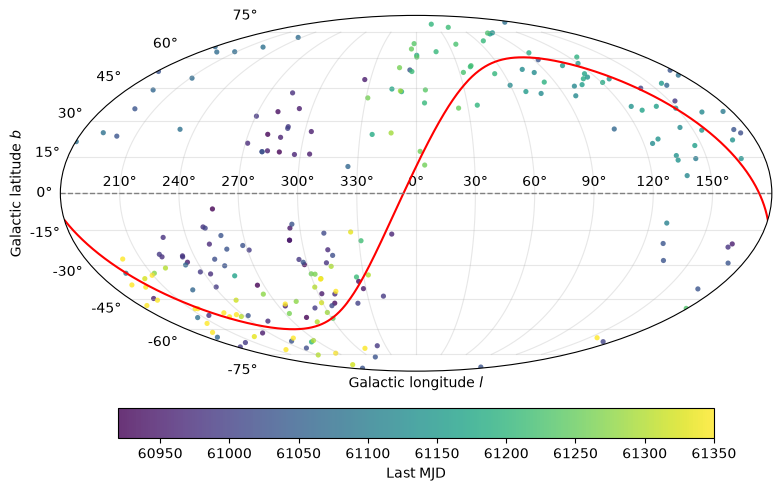

In [10]:
fig = plt.figure(figsize=(11, 6))
ax = fig.add_subplot(projection="mollweide")

t = np.linspace(0, 360, 2000) * u.deg

# Ecliptic
ecl = SkyCoord(lon=t, lat=np.zeros(t.size)*u.deg, frame=GeocentricTrueEcliptic).galactic
el = -ecl.l.wrap_at(180*u.deg).radian
eb = ecl.b.radian
idx = np.argsort(el)
ax.plot(el[idx], eb[idx], color="red", lw=1.5, label="Ecliptic")

# Galactic plane
ax.axhline(0, color="gray", lw=1, ls="--", label="Galactic plane")

# Data (newest on top)
c = SkyCoord(ra=df_snia["meanra"].to_numpy()*u.deg, dec=df_snia["meandec"].to_numpy()*u.deg).galactic
l = -c.l.wrap_at(180*u.deg).radian
b = c.b.radian
mjd = df_snia["lastmjd"].to_numpy()
o = np.argsort(mjd)
sc = ax.scatter(l[o], b[o], s=14, c=mjd[o], cmap="viridis", alpha=0.8, edgecolor="none")

ax.set_xticklabels(["210°", "240°", "270°", "300°", "330°", "0°", "30°", "60°", "90°", "120°", "150°"])
ax.set_xlabel("Galactic longitude $l$")
ax.set_ylabel("Galactic latitude $b$")
ax.grid(True, alpha=0.3)
fig.colorbar(sc, ax=ax, orientation="horizontal", label="Last MJD", pad=0.08, shrink=0.7)
plt.show()


Cada posición (RA = α, Dec = δ) se convierte en un punto sobre la esfera unidad:

$$\hat r = (\cos\delta\cos\alpha, \cos\delta\sin\alpha, \sin\delta)$$

Astropy construye un árbol KD (`scipy.spatial.cKDTree`) con los vectores del catálogo (`coords_tns`). Luego consulta, para cada candidata, el punto más cercano en distancia euclídea (la cuerda). Esto es O(N log M), en vez de O(N·M) comparando todos contra todos.
Si dos puntos unitarios están separados por una cuerda $c$, el ángulo entre ellos es:

$$\theta = 2\arcsin \left(\dfrac c2\right)$$

Este $\theta$ es `sep2d`.


Querying TNS public objects...
Número de objetos en TNS: 191101
Index(['objid', 'name_prefix', 'name', 'ra', 'declination', 'redshift',
       'typeid', 'type', 'reporting_groupid', 'reporting_group',
       'source_groupid', 'source_group', 'discoverydate', 'discoverymag',
       'discmagfilter', 'filter', 'reporters', 'time_received',
       'internal_names', 'Discovery_ADS_bibcode', 'Class_ADS_bibcodes',
       'creationdate', 'lastmodified'],
      dtype='str')


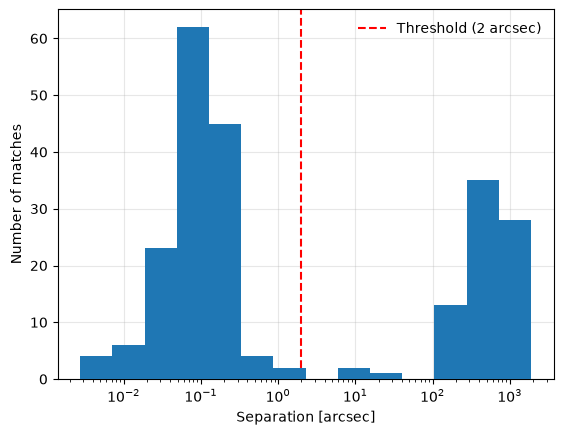

In [11]:
print("\nQuerying TNS public objects...")
tns = pd.read_csv("data/tns_public_objects.csv", skiprows=1, low_memory=False)
print("Número de objetos en TNS:", len(tns))
print(tns.columns)

#print("\nColumnas TNS:")
#print(tns.columns.tolist())

# Convierte las columnas a tipo numérico, ignorando errores
# Además, eliminamos filas con valores NaN en las columnas de coordenadas
tns["ra"]          = pd.to_numeric(tns["ra"], errors="coerce")
tns["declination"] = pd.to_numeric(tns["declination"], errors="coerce")
tns["redshift"]    = pd.to_numeric(tns["redshift"], errors="coerce")
tns = tns.dropna(subset=["ra", "declination"]).reset_index(drop=True)

# Cambio de coordenadas
coords_snia = SkyCoord(ra=df_snia["meanra"].values * u.deg, dec=df_snia["meandec"].values * u.deg)
coords_tns  = SkyCoord(ra=tns["ra"].values * u.deg, dec=tns["declination"].values * u.deg)

# Matching usando match_to_catalog_sky
# El método match_to_catalog_sky encuentra el objeto más cercano en el catálogo de TNS para cada objeto en df_snia
# Devuelve tres valores:
# - idx:    los índices de los objetos coincidentes en el catálogo de TNS
# - sep2d:  la separación angular entre los objetos coincidentes
# - dist3d: la separación 3D (no se utiliza en este caso)
# Se pueden cambiar los siguientes parámetros:
# - nthneighbor: el número de vecinos a considerar (por defecto es 1, es decir, el vecino más cercano)
# - storekdtree: si se debe almacenar el árbol k-d para acelerar las búsquedas (por defecto es True)
# - max_sep: la separación máxima para considerar un objeto como coincidente, 
# puede ser un valor en arcsec (por ejemplo, 2.0 * u.arcsec)
idx, sep2d, dist3d = coords_snia.match_to_catalog_sky(coords_tns)



fig, ax = plt.subplots()
n    = int(np.sqrt(len(sep2d)))  # Número de bins usando la regla de raíz cuadrada
bins = np.logspace(np.log10(sep2d.arcsec.min()), np.log10(sep2d.arcsec.max()), n)
ax.hist(sep2d.arcsec, bins=bins, zorder=3)
ax.set_xscale("log")
ax.axvline(2, color="red", ls="--", label="Threshold (2 arcsec)")
ax.set_xlabel("Separation [arcsec]")
ax.set_ylabel("Number of matches")
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
plt.show()

In [12]:
# Habiendo visualizado la distribución de separaciones, podemos establecer un umbral de matching.
# siendo este de 2 arcsec.
threshold_sep = 2.0 * u.arcsec
matched = sep2d <= threshold_sep

df_snia["tns_match"] = matched
df_snia["tns_sep_arcsec"] = sep2d.arcsec

cols = {"name": "tns_name", "name_prefix": "tns_name_prefix", "type": "tns_type", "redshift": "tns_redshift"}

tns_matched = (
    tns.iloc[idx][list(cols)]
    .rename(columns=cols)
    .set_index(df_snia.index)
)

tns_matched.loc[~matched] = np.nan   # blank out rows without a match
df_snia[tns_matched.columns] = tns_matched
df_snia["tns_full_name"] = (df_snia["tns_name_prefix"] + " " + df_snia["tns_name"]).where(matched)

print("\nMatches encontrados:", int(df_snia["tns_match"].sum()))
display(df_snia.head())


Matches encontrados: 146


,oid,ndethist,ncovhist,mjdstarthist,mjdendhist,corrected,stellar,ndet,g_r_max,g_r_max_corr,...,classifier,probability,step_id_corr,tns_match,tns_sep_arcsec,tns_name,tns_name_prefix,tns_type,tns_redshift,tns_full_name
0,ZTF26abwqfcv,58,2160,61304.507824,61350.405197,True,False,57,None,None,...,lc_classifier_BHRF_forced_phot,0.664668,27.6.0,False,1821.249040,NaN,NaN,NaN,NaN,NaN
1,ZTF26absfire,173,4221,61286.426030,61350.391123,False,False,172,None,None,...,lc_classifier_BHRF_forced_phot,0.713136,27.6.0,False,516.541359,NaN,NaN,NaN,NaN,NaN
2,ZTF26abnuiar,127,3170,61264.487512,61350.382211,False,False,127,None,None,...,lc_classifier_BHRF_forced_phot,0.655720,27.6.0,False,1113.374688,NaN,NaN,NaN,NaN,NaN
3,ZTF26acbezdh,31,1925,61327.421296,61350.382211,False,False,30,None,None,...,lc_classifier_BHRF_forced_phot,0.742608,27.6.0,False,1046.942230,NaN,NaN,NaN,NaN,NaN
4,ZTF26abpbqtk,224,3276,61269.475162,61350.382211,True,False,233,None,None,...,lc_classifier_BHRF_forced_phot,0.656476,27.6.0,False,426.464975,NaN,NaN,NaN,NaN,NaN


# Light Curves

In [15]:
client = Alerce()
outdir = "data"
os.makedirs(outdir, exist_ok=True)

queries = {
    "detections":     client.query_detections,
    "non_detections": client.query_non_detections,
    "forced_phot":    client.query_forced_photometry,
}
tables = {name: [] for name in queries}

pbar = tqdm(df_snia["oid"], desc="Downloading")
for oid in pbar:
    pbar.set_postfix(oid=oid)
    for name, query in queries.items():
        try: tbl = query(oid, format="pandas")
        except: continue
        if tbl is not None and len(tbl) > 0: tables[name].append(tbl.assign(oid=oid))

for name, parts in tables.items():
    if parts:
        df_out = pd.concat(parts, ignore_index=True)
        df_out.to_parquet(f"{outdir}/snia_{name}.parquet", index=False)
        print(f"{name}: {len(df_out)} filas -> {outdir}/snia_{name}.parquet")
    else:
        print(f"{name}: nada que guardar")


Downloading: 100%|██████████| 226/226 [07:58<00:00,  2.12s/it, oid=ZTF25aaqqcld]


detections: 13416 filas -> data/snia_detections.parquet
non_detections: 10830 filas -> data/snia_non_detections.parquet
forced_phot: 17133 filas -> data/snia_forced_phot.parquet


In [19]:
snia_forced         = pd.read_parquet(f"data/snia_forced.parquet")
snia_detections     = pd.read_parquet(f"data/snia_detections.parquet")
snia_non_detections = pd.read_parquet(f"data/snia_non_detections.parquet")

print('Columns forced:\n', snia_forced.columns.tolist())
print('Columns detections:\n', snia_detections.columns.tolist())
print('Columns non-detections:\n', snia_non_detections.columns.tolist())

Columns forced:
 ['candid', 'tid', 'pid', 'oid', 'mjd', 'fid', 'ra', 'e_ra', 'dec', 'e_dec', 'mag', 'e_mag', 'mag_corr', 'e_mag_corr', 'e_mag_corr_ext', 'isdiffpos', 'corrected', 'dubious', 'parent_candid', 'has_stamp', 'rfid', 'clrcoeff', 'ranr', 'sciinpseeing', 'clrcounc', 'decnr', 'scibckgnd', 'exptime', 'magnr', 'scisigpix', 'adpctdif1', 'sigmagnr', 'magzpsci', 'adpctdif2', 'chinr', 'diffmaglim', 'programid', 'sharpnr', 'field', 'magzpsciunc', 'procstatus', 'rcid', 'magzpscirms', 'distnr']
Columns detections:
 ['tid', 'mjd', 'candid', 'fid', 'pid', 'diffmaglim', 'isdiffpos', 'nid', 'distnr', 'magpsf', 'magpsf_corr', 'magap', 'sigmapsf', 'sigmapsf_corr', 'sigmapsf_corr_ext', 'sigmagap', 'ra', 'dec', 'rb', 'rbversion', 'drb', 'magapbig', 'sigmagapbig', 'rfid', 'has_stamp', 'corrected', 'dubious', 'step_id_corr', 'phase', 'parent_candid', 'oid']
Columns non-detections:
 ['tid', 'mjd', 'fid', 'diffmaglim', 'oid']


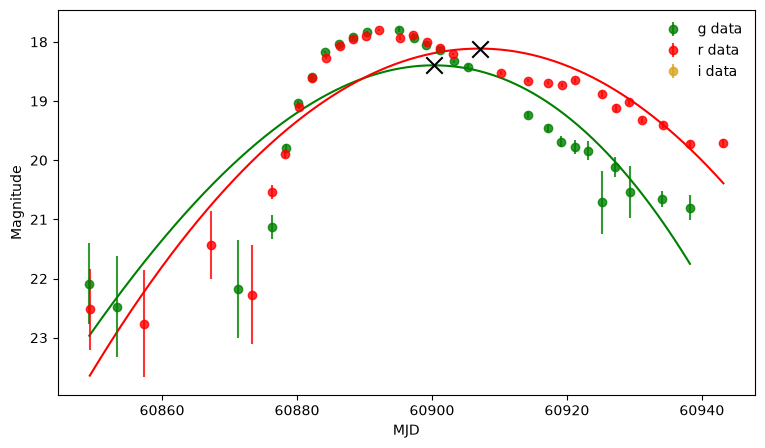

In [34]:
oid_selected = np.random.choice(df_snia["oid"].values, size=1)[0]
show_nondet  = True
DEGREE       = 3 # Grado del polinomio para el ajuste de la curva de luz

fo = snia_forced[snia_forced["oid"] == oid_selected]
nd = snia_non_detections[snia_non_detections["oid"] == oid_selected]

# Eliminar sentinels y non-measurements
fo = fo[(fo.mag < 99) & (fo.e_mag < 1)]

bands = {1: ("g", "green"), 2: ("r", "red"), 3: ("i", "goldenrod")}

fig, ax = plt.subplots(figsize=(9,5))
for fid, (name, color) in bands.items():
    sndata = fo[fo.fid == fid]
    ax.errorbar(
        sndata.mjd, sndata.mag, yerr=sndata.e_mag,
        fmt="o", color=color, label=f"{name} data",
        alpha=0.8, zorder=2
    )
    
    if len(sndata) > DEGREE:
        x, y = sndata["mjd"].values, sndata["mag"].values
        poly = np.poly1d(np.polyfit(x, y, DEGREE))
        xfit = np.linspace(x.min(), x.max(), 500)
        yfit = poly(xfit)
        ax.plot(xfit, yfit, color=color, zorder=1)
        i = np.argmin(yfit)
        ax.scatter(xfit[i], yfit[i], color="black", marker="x", s=140, zorder=5)

ax.invert_yaxis()
ax.set_xlabel("MJD")
ax.set_ylabel("Magnitude")
ax.legend(frameon=False)
plt.show()

In [30]:
# Conversiones de magnitudes de ZTF a Johnson-Cousins
# usando el Jeste et al. 2005 (https://ui.adsabs.harvard.edu/abs/2005AJ....130..873J/abstract)

gr2B = lambda g,r: g+0.39*(g-r)+0.21
gr2V = lambda g,r: g-0.58*(g-r)-0.01

